## CE2 Phase 8: Bias-Variance Trade-off, Overfitting & Underfitting

### 1. Conceptual Foundations: Underfitting vs. Overfitting
In statistical learning, a model's generalization error on unseen data is governed by the trade-off between two opposing error sources:
* **Underfitting (High Bias):** Occurs when a model is overly simplistic and lacks the functional capacity to capture the underlying data patterns. Both training error and cross-validation error are high and converge closely together. Increasing model capacity or adding relevant features helps alleviate high bias.
* **Overfitting (High Variance):** Occurs when a model has excessive capacity relative to the sample size and learns the random noise and sample idiosyncrasies of the training data rather than true underlying relationships. Training error continues to decrease, but validation error increases sharply, resulting in a large generalization gap. Regularization, dimensionality reduction, or more training data helps reduce variance.

---

### 2. Expected Squared Error Decomposition
Mathematically, for any regression estimator $\hat{f}(x)$ trained on dataset $\mathcal{D}$ predicting target $y = f(x) + \epsilon$ with zero-mean noise variance $\sigma^2$, the expected out-of-sample prediction error decomposes additively:

$$\mathbb{E}_{\mathcal{D}, \epsilon}\left[(y - \hat{f}(x))^2\right] = \underbrace{\left(f(x) - \mathbb{E}[\hat{f}(x)]\right)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}\left[\left(\hat{f}(x) - \mathbb{E}[\hat{f}(x)]\right)^2\right]}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{Irreducible Noise}}$$

* **Bias$^2$:** The error introduced by approximating a complex real-world phenomenon with a simplified mathematical model family.
* **Variance:** The sensitivity of the model's predictions to fluctuations in the specific training sample drawn.
* **Irreducible Error ($\sigma^2$):** Inherent stochastic noise, unmeasured latent features, and biometric measurement uncertainty that cannot be reduced by any model.

---

### 3. Diagnostic Toolset
To diagnose where our facial feature models sit on the bias-variance spectrum, we deploy three complementary diagnostic lenses:
1. **Model Complexity Curves:** Tracking training, 5-fold cross-validation, and holdout test error as a function of polynomial expansion degree ($d \in [1, 4]$).
2. **Empirical Learning Curves:** Tracking training and validation RMSE as training sample size ($N$) increases from 10% to 100%, revealing sample efficiency and asymptotic error bounds.
3. **Bootstrap Bias-Variance Decomposition:** Drawing $B = 100$ bootstrap resamples to empirically separate estimation variance from squared bias plus irreducible noise.

> **Methodological Caveat:** Because the true physiological age function $f(x)$ is unknown in empirical datasets, the calculated empirical "Bias$^2$" term necessarily includes the irreducible noise $\sigma^2$. It serves as a rigorous upper-bound proxy used for **relative model comparison**, rather than an isolated ground-truth quantity.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_validate, learning_curve
from sklearn.metrics import mean_squared_error, r2_score

# Ensure relative paths work from project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Load unscaled datasets
X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Define feature partitions
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]
dummy_cols = ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

# Drop reference categories (gender_0, race_0) to prevent the dummy variable trap
X_train = X_train.drop(columns=["gender_0", "race_0"])
X_test = X_test.drop(columns=["gender_0", "race_0"])

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

# Model factory creating a leakage-free pipeline with selective polynomial expansion
def make_model(degree):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("poly", Pipeline([
                ("scale", StandardScaler()),
                ("poly", PolynomialFeatures(degree=degree, include_bias=False))
            ]), continuous_cols),
            ("dummies", "passthrough", dummy_cols)
        ])),
        ("reg", LinearRegression())
    ])

# 5-Fold cross-validation configuration
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Reference baseline RMSE (naive training mean predictor)
baseline_rmse = y_train.std(ddof=0)
print(f"Baseline Reference RMSE (always predicting training mean age): {baseline_rmse:.4f} years")


X_train shape: (2398, 12)
X_test shape:  (600, 12)
y_train shape: (2398,)
y_test shape:  (600,)
Baseline Reference RMSE (always predicting training mean age): 20.0591 years



In [2]:
# Model Complexity Sweep across degrees 1 to 4
complexity_rows = []

for degree in range(1, 5):
    model = make_model(degree)
    
    # 5-fold cross-validation on training data only
    cv_res = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error", return_train_score=True
    )
    
    # Fit full model on training data for holdout test evaluation
    model.fit(X_train, y_train)
    y_test_pred = model.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    test_r2 = r2_score(y_test, y_test_pred)
    
    # Metrics calculation
    train_rmse = -np.mean(cv_res["train_score"])
    cv_rmse_mean = -np.mean(cv_res["test_score"])
    cv_rmse_std = np.std(cv_res["test_score"])
    n_features = model.named_steps["prep"].transform(X_train).shape[1]
    gap = cv_rmse_mean - train_rmse
    ratio = cv_rmse_mean / train_rmse
    
    complexity_rows.append({
        "Degree": degree,
        "Features": n_features,
        "Train_RMSE": train_rmse,
        "CV_RMSE_Mean": cv_rmse_mean,
        "CV_RMSE_Std": cv_rmse_std,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2,
        "Gap (CV - Train)": gap,
        "Ratio (CV / Train)": ratio
    })

df_complexity = pd.DataFrame(complexity_rows)
print(f"Reference Baseline RMSE: {baseline_rmse:.4f} years")
print()
print("Model Complexity Evaluation Table (Degrees 1 to 4):")
print(df_complexity.round(4).to_string(index=False))


Reference Baseline RMSE: 20.0591 years

Model Complexity Evaluation Table (Degrees 1 to 4):
 Degree  Features  Train_RMSE  CV_RMSE_Mean  CV_RMSE_Std  Test_RMSE  Test_R2  Gap (CV - Train)  Ratio (CV / Train)
      1        12     18.1844       18.3230       0.5747    19.1813   0.1719            0.1386              1.0076
      2        40     17.9491       18.5484       0.6956    19.1044   0.1785            0.5993              1.0334
      3       124     17.5825       20.8010       3.4186    19.5859   0.1366            3.2184              1.1830
      4       334     17.0786       84.0636      70.5022    24.3899  -0.3390           66.9850              4.9222



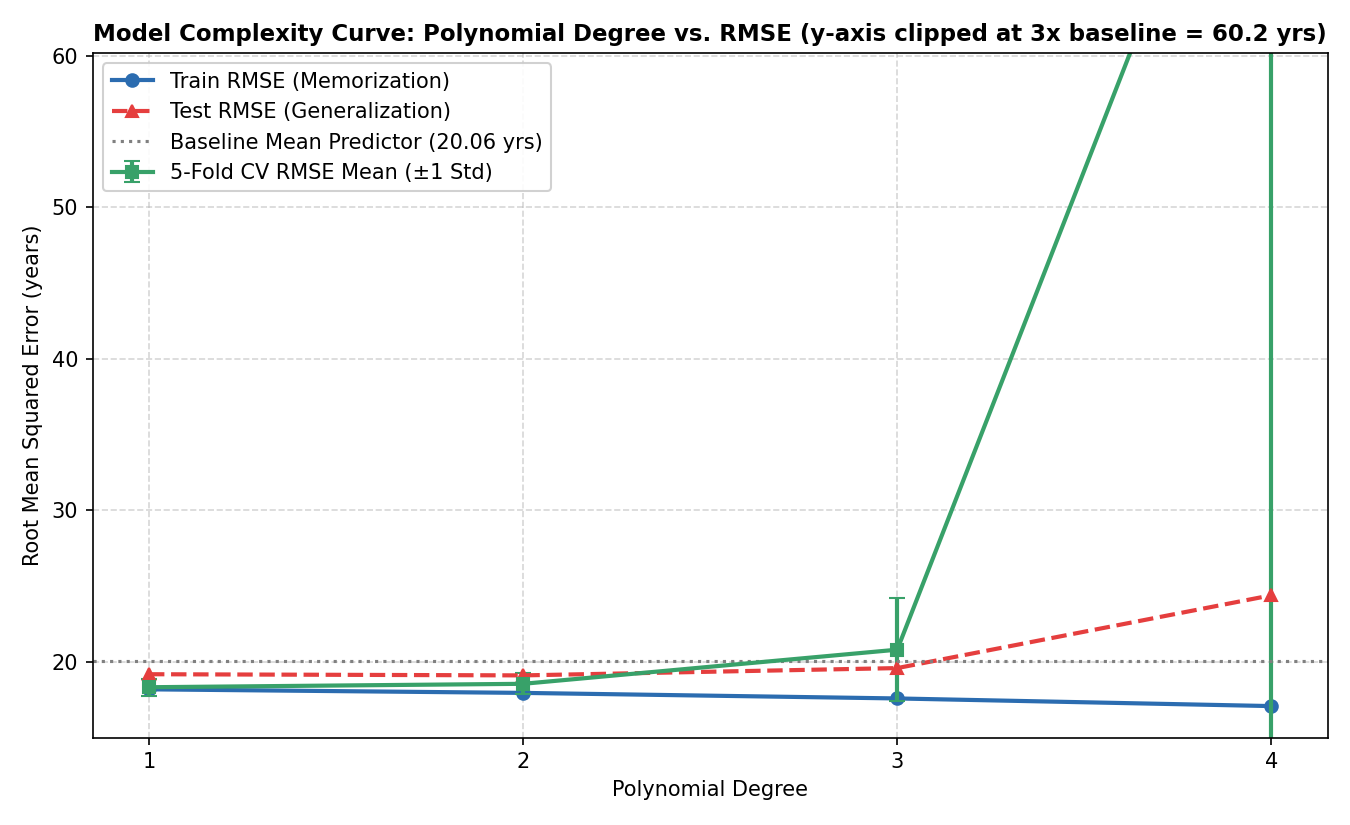

In [3]:
# Plot Complexity Curve: Degree vs Train RMSE, CV RMSE, and Test RMSE
degrees = df_complexity["Degree"]
train_rmse_vals = df_complexity["Train_RMSE"]
cv_rmse_vals = df_complexity["CV_RMSE_Mean"]
cv_rmse_stds = df_complexity["CV_RMSE_Std"]
test_rmse_vals = df_complexity["Test_RMSE"]

plt.figure(figsize=(9, 5.5))

# Plot performance curves
plt.plot(degrees, train_rmse_vals, marker='o', color='#2b6cb0', linewidth=2, label='Train RMSE (Memorization)')
plt.errorbar(degrees, cv_rmse_vals, yerr=cv_rmse_stds, marker='s', color='#38a169', linewidth=2, capsize=4, label='5-Fold CV RMSE Mean (±1 Std)')
plt.plot(degrees, test_rmse_vals, marker='^', color='#e53e3e', linewidth=2, linestyle='--', label='Test RMSE (Generalization)')

# Reference baseline line
plt.axhline(baseline_rmse, color='gray', linestyle=':', linewidth=1.5, label=f'Baseline Mean Predictor ({baseline_rmse:.2f} yrs)')

# Check if any metric exceeds 3x baseline RMSE and clip y-axis
y_limit_threshold = 3.0 * baseline_rmse
all_vals = list(train_rmse_vals) + list(cv_rmse_vals) + list(test_rmse_vals)
if any(v > y_limit_threshold for v in all_vals):
    plt.ylim(15.0, y_limit_threshold)
    plt.title(f"Model Complexity Curve: Polynomial Degree vs. RMSE (y-axis clipped at 3x baseline = {y_limit_threshold:.1f} yrs)", fontsize=11, fontweight="bold")
else:
    plt.title("Model Complexity Curve: Polynomial Degree vs. RMSE", fontsize=12, fontweight="bold")

plt.xlabel("Polynomial Degree", fontsize=10)
plt.ylabel("Root Mean Squared Error (years)", fontsize=10)
plt.xticks(degrees)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper left")
plt.tight_layout()

plt.savefig("visualizations/15_complexity_curve.png", dpi=150)
plt.show()


Learning Curve Summary (Smallest vs. Largest Training Size):
Degree 1: Smallest N= 191 -> Train RMSE=18.5812, CV RMSE=18.7293 | Largest N=1918 -> Train RMSE=18.1837, CV RMSE=18.3217
Degree 2: Smallest N= 191 -> Train RMSE=16.8631, CV RMSE=27.4124 | Largest N=1918 -> Train RMSE=17.9483, CV RMSE=18.5496
Degree 3: Smallest N= 191 -> Train RMSE=13.2899, CV RMSE=265.5266 | Largest N=1918 -> Train RMSE=17.5823, CV RMSE=20.7934



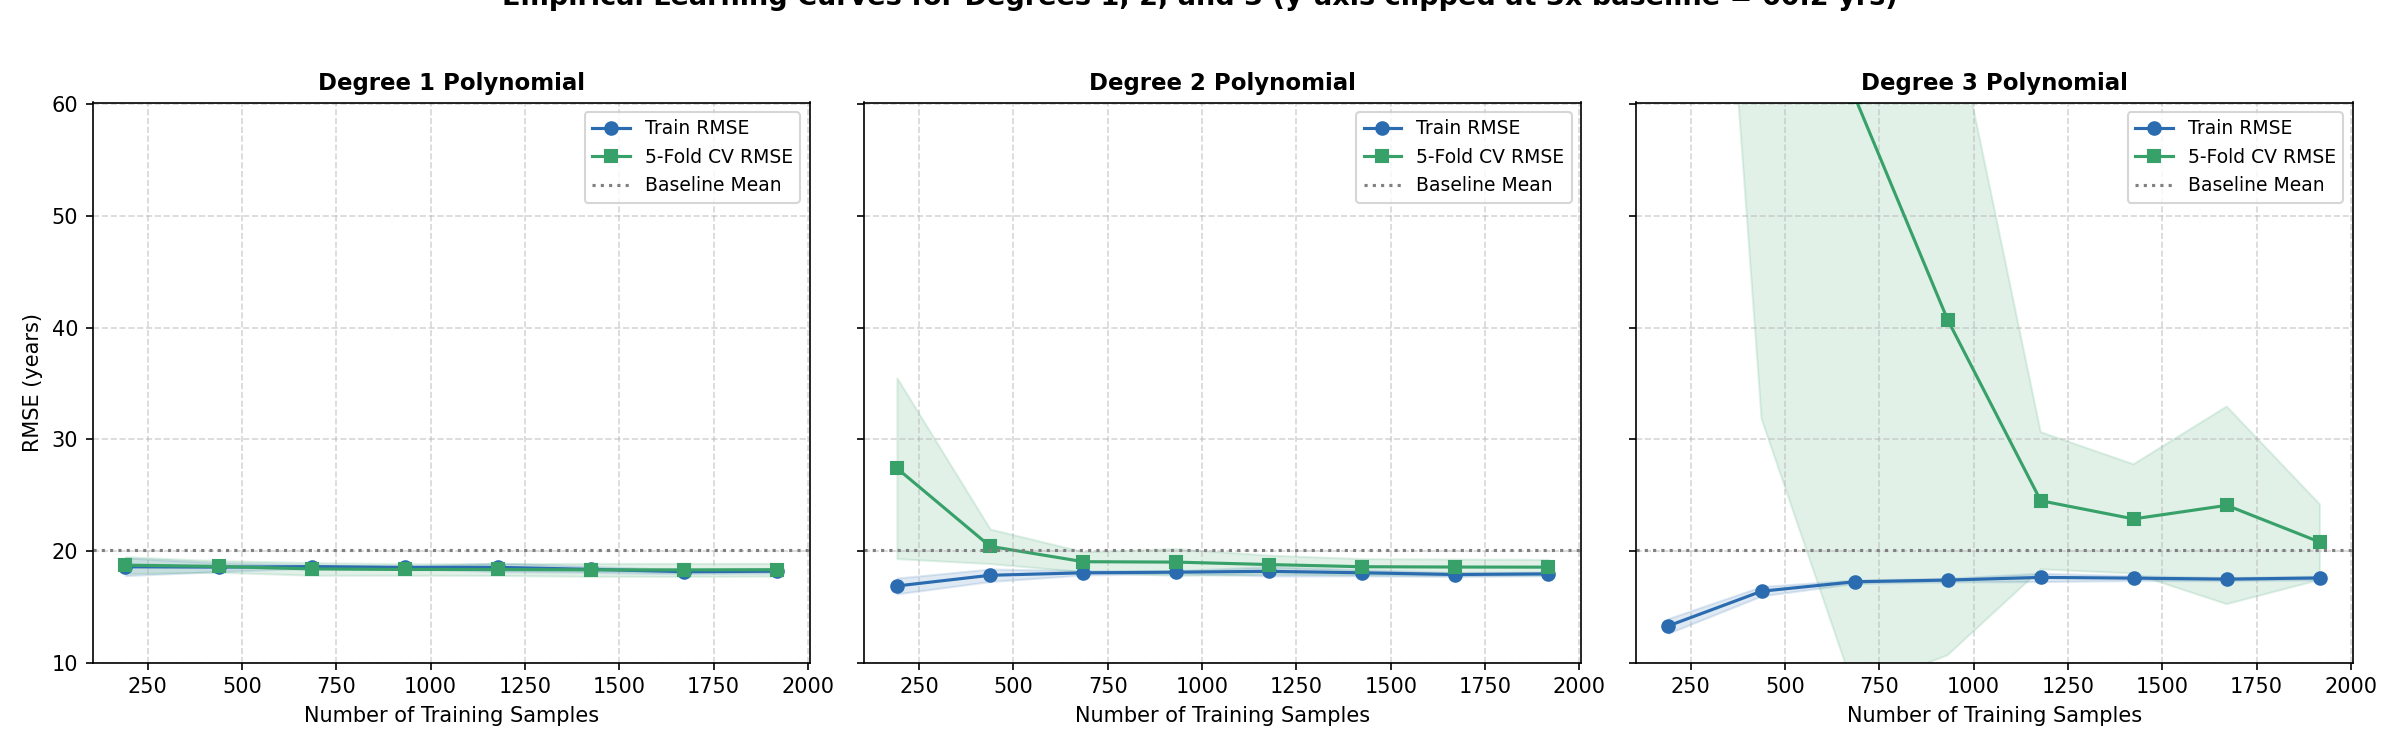

In [4]:
# Compute empirical learning curves across sample sizes for degrees 1, 2, and 3
degrees_to_plot = [1, 2, 3]
train_fraction_sizes = np.linspace(0.1, 1.0, 8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
y_clip_limit = 3.0 * baseline_rmse

print("Learning Curve Summary (Smallest vs. Largest Training Size):")

for idx, d in enumerate(degrees_to_plot):
    train_sizes, train_scores, test_scores = learning_curve(
        make_model(d), X_train, y_train,
        train_sizes=train_fraction_sizes, cv=cv,
        scoring="neg_root_mean_squared_error",
        shuffle=True, random_state=42
    )
    
    # Calculate RMSE means and standard deviations
    tr_rmse_mean = -np.mean(train_scores, axis=1)
    tr_rmse_std = np.std(train_scores, axis=1)
    cv_rmse_mean = -np.mean(test_scores, axis=1)
    cv_rmse_std = np.std(test_scores, axis=1)
    
    print(f"Degree {d}: Smallest N={train_sizes[0]:4d} -> Train RMSE={tr_rmse_mean[0]:.4f}, CV RMSE={cv_rmse_mean[0]:.4f} | Largest N={train_sizes[-1]:4d} -> Train RMSE={tr_rmse_mean[-1]:.4f}, CV RMSE={cv_rmse_mean[-1]:.4f}")
    
    ax = axes[idx]
    ax.plot(train_sizes, tr_rmse_mean, marker='o', color='#2b6cb0', label='Train RMSE')
    ax.fill_between(train_sizes, tr_rmse_mean - tr_rmse_std, tr_rmse_mean + tr_rmse_std, color='#2b6cb0', alpha=0.15)
    
    ax.plot(train_sizes, cv_rmse_mean, marker='s', color='#38a169', label='5-Fold CV RMSE')
    ax.fill_between(train_sizes, cv_rmse_mean - cv_rmse_std, cv_rmse_mean + cv_rmse_std, color='#38a169', alpha=0.15)
    
    ax.axhline(baseline_rmse, color='gray', linestyle=':', linewidth=1.5, label='Baseline Mean')
    
    ax.set_title(f"Degree {d} Polynomial", fontsize=11, fontweight="bold")
    ax.set_xlabel("Number of Training Samples", fontsize=10)
    if idx == 0:
        ax.set_ylabel("RMSE (years)", fontsize=10)
    ax.set_ylim(10.0, y_clip_limit)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True, fontsize=9)

plt.suptitle(f"Empirical Learning Curves for Degrees 1, 2, and 3 (y-axis clipped at 3x baseline = {y_clip_limit:.1f} yrs)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

plt.savefig("visualizations/14_learning_curves.png", dpi=150)
plt.show()


In [5]:
# Note: The empirical Bias^2 term calculated here includes irreducible noise (sigma^2)
# because the true latent aging function f(x) is unknown. It serves as a rigorous relative benchmark.

rng = np.random.default_rng(42)
B = 100
n_train = len(X_train)
n_test = len(X_test)

bias_var_rows = []

for degree in range(1, 5):
    predictions = np.zeros((B, n_test))
    
    for b in range(B):
        # Draw bootstrap sample of training indices with replacement
        boot_idx = rng.choice(n_train, size=n_train, replace=True)
        X_boot = X_train.iloc[boot_idx]
        y_boot = y_train.iloc[boot_idx]
        
        model = make_model(degree)
        model.fit(X_boot, y_boot)
        predictions[b] = model.predict(X_test)
    
    # Expected predictions across ensemble
    mean_pred = predictions.mean(axis=0)
    
    # Decomposition metrics
    bias2 = np.mean((mean_pred - y_test)**2)
    variance = np.mean(predictions.var(axis=0))
    avg_test_mse = np.mean([mean_squared_error(y_test, predictions[b]) for b in range(B)])
    check = bias2 + variance
    diff = abs(check - avg_test_mse)
    
    if diff > 1e-6:
        print(f"WARNING: Degree {degree} Bias-Variance identity discrepancy ({diff:.8f}) exceeds 1e-6!")
    
    bias_var_rows.append({
        "Degree": degree,
        "Bias2": bias2,
        "Variance": variance,
        "Bias2+Variance": check,
        "Avg_Test_MSE": avg_test_mse
    })

df_bias_var = pd.DataFrame(bias_var_rows)
print("Bootstrap Bias-Variance Decomposition Results (B = 100 Resamples):")
print(df_bias_var.round(4).to_string(index=False))

# Persist decomposition results
df_bias_var.to_csv("data/processed/ce2_bias_variance_results.csv", index=False)
print()
print("Saved decomposition results to data/processed/ce2_bias_variance_results.csv")


Bootstrap Bias-Variance Decomposition Results (B = 100 Resamples):
 Degree    Bias2  Variance  Bias2+Variance  Avg_Test_MSE
      1 368.2339    1.5856        369.8196      369.8196
      2 365.3276    5.0790        370.4066      370.4066
      3 386.6605   23.5827        410.2432      410.2432
      4 549.6830  404.7666        954.4496      954.4496

Saved decomposition results to data/processed/ce2_bias_variance_results.csv



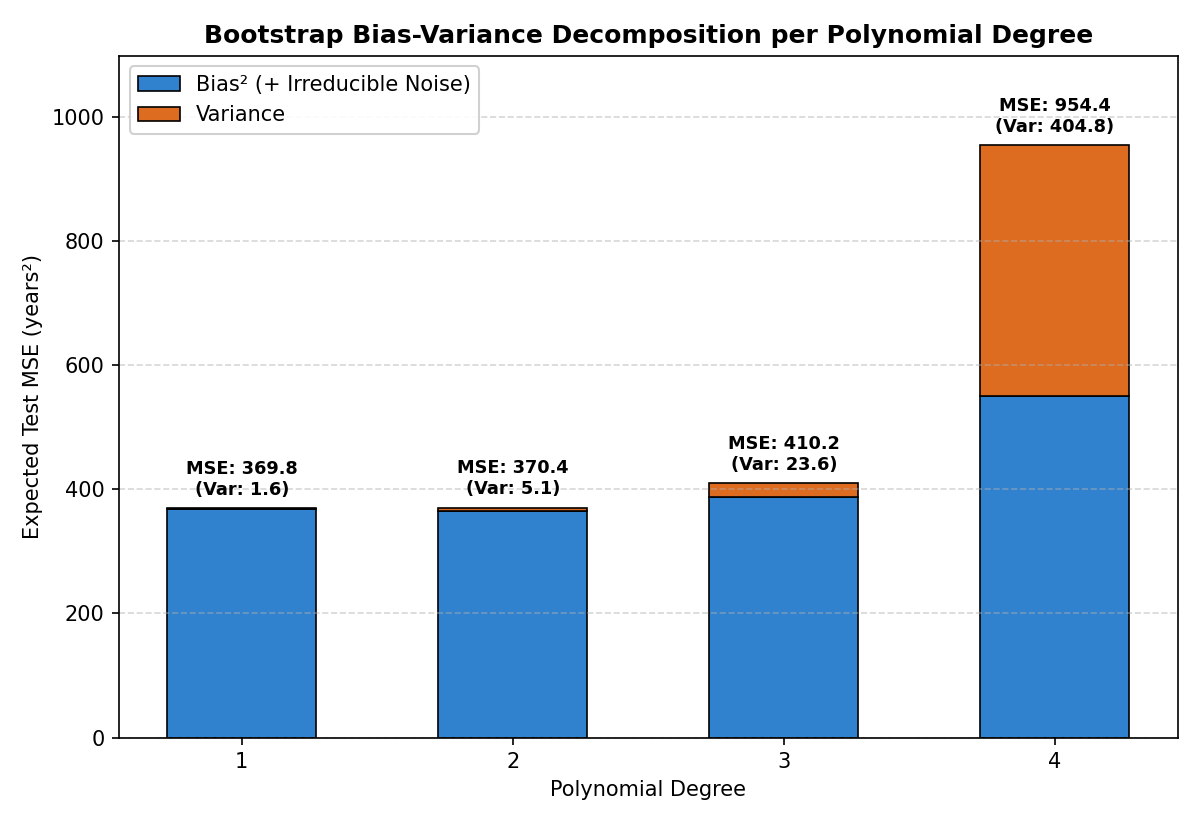

In [6]:
# Stacked bar chart of Bias^2 and Variance per degree
degrees = df_bias_var["Degree"]
bias2_vals = df_bias_var["Bias2"]
var_vals = df_bias_var["Variance"]
total_mse = df_bias_var["Avg_Test_MSE"]

fig, ax = plt.subplots(figsize=(8, 5.5))
bar_width = 0.55

# Check if Variance for degree 4 is more than 5x the largest other bar
var_deg4 = var_vals.iloc[-1]
max_other_bar = total_mse.iloc[:-1].max()
use_log = var_deg4 > (5.0 * max_other_bar)

bars_bias = ax.bar(degrees, bias2_vals, width=bar_width, color='#3182ce', label='Bias² (+ Irreducible Noise)', edgecolor='black', linewidth=0.8)
bars_var = ax.bar(degrees, var_vals, width=bar_width, bottom=bias2_vals, color='#dd6b20', label='Variance', edgecolor='black', linewidth=0.8)

# Add numerical labels on top of stacked bars
for idx, (b_val, v_val, tot) in enumerate(zip(bias2_vals, var_vals, total_mse)):
    deg = degrees.iloc[idx]
    ax.text(deg, tot + 15.0, f"MSE: {tot:.1f} (Var: {v_val:.1f})", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

if use_log:
    ax.set_yscale('log')
    ax.set_title("Bootstrap Bias-Variance Decomposition per Degree (Log Scale: Deg 4 Variance > 5x Other Bars)", fontsize=11, fontweight="bold")
else:
    ax.set_title("Bootstrap Bias-Variance Decomposition per Polynomial Degree", fontsize=12, fontweight="bold")

ax.set_xlabel("Polynomial Degree", fontsize=10)
ax.set_ylabel("Expected Test MSE (years²)", fontsize=10)
ax.set_xticks(degrees)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper left")
plt.tight_layout()

plt.savefig("visualizations/16_bias_variance_decomposition.png", dpi=150)
plt.show()


### Observation

*(This section is reserved for user observations and qualitative synthesis regarding the empirical bias-variance trade-off, learning curve convergence, and complexity dynamics across model orders.)*
